# Import a Biacore Cycle/sample text export

Import **`biacore_cycle_sample.tsv`**, inspect its metadata, and plot the measured
sensorgrams. This example uses a full-resolution selection committed with the repository;
it uses pyKinGenie's one-site fitter and compares its output with the author report. No data download is required.

**Data origin:** [Duke TitrationAnalysis T200 example](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Example%20T200%20Chip%201%20Channel%202.txt). TitrationAnalysis tool, Kan Li and S Moses Dennison, Duke University. [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
This is a modified excerpt/conversion; the exact changes and pinned sources
are listed in [SOURCES.md](data/spr_exports/SOURCES.md).
The data and plotted sensorgrams retain their upstream license:
[full license notice](../test_files/spr_exports/TitrationAnalysis-LICENSE).

In [1]:
from pathlib import Path
import sys
import warnings
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

# Works from the repository root, notebooks/, or docs/notebooks/.
cwd = Path.cwd().resolve()
repo_root = next(
    path for path in (cwd, *cwd.parents)
    if (path / "src" / "pykingenie").is_dir()
    and (path / "test_files" / "spr_exports").is_dir()
)
for path in [repo_root / "src"]:
    sys.path.insert(0, str(path))
from pykingenie import detect_file_format, SprTextExperiment, KineticsAnalyzer, plot_plate_info

plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
data_file = repo_root / "notebooks" / "data" / "spr_exports" / "biacore_cycle_sample.tsv"
print("Input:", data_file.name)
fit_metadata = json.loads((data_file.parent / "fit_metadata.json").read_text())[data_file.stem]

Input: biacore_cycle_sample.tsv


## File layout and published five-curve selection

Tab-separated X/Y pairs for **cycles 18–22**, the five curves shown on page 1
of the author sensorgram report. Their concentrations are **221.7, 443.4,
886.8, 1774, 3547 nM**, verified against that figure and the original sample sheet.
The original labels include mass/truncated units; molar values are supplied
explicitly from the source metadata.

Retain all finite observations in the author protocol window **−60 to 780 s**,
at native sampling. Counts are **8,221 / 8,391 / 8,400 / 8,392 / 8,400**.
The original has 179, 9, 0, 8, 0 missing/non-finite pairs, respectively; only
those pairs are omitted, together with 16 observations outside the protocol
window. Missing values are not interpolated or replaced. The Windows-1252
source is transcoded to UTF-8 without changing its decoded labels or values.

Association is `[0, 180)` s; dissociation is 180–780 s, from the original sample
sheet. The raw plot rejoins all partitions on each original time grid.
`sample_id` is the analyte identity from that sheet.

In [2]:
association_start = fit_metadata["association_start"]
association_end = fit_metadata["association_end"]

print("Detected layout:", detect_file_format(data_file))

experiment = SprTextExperiment("biacore_cycle_sample")
with warnings.catch_warnings(record=True) as messages:
    warnings.simplefilter("always", UserWarning)
    experiment.read_file(
        data_file,
        association_start=association_start,
        association_end=association_end,
        decimal='.',
        time_unit="s",
        sample_id=fit_metadata["analyte"],
        concentrations=fit_metadata["concentrations"],
        concentration_unit="uM",
    )
for message in messages:
    print(message.message)
print(f"Imported {experiment.no_sensors} measured curves; {experiment.no_steps} API phases.")
assert experiment.traces_loaded and experiment.no_sensors == 5
assert experiment.no_sensors == fit_metadata["literature_reference"]["curves_fitted"]
np.testing.assert_allclose(
    experiment.ligand_conc_df["Concentration_micromolar"].to_numpy() * 1000,
    fit_metadata["literature_reference"]["concentrations_nM"],
)

Detected layout: spr_text
Imported 5 measured curves; 3 API phases.


## Available curve information

Each measured curve becomes a sensor in the experiment object. Its complete
original label remains in `sensor_names`. The following table extracts only
the header/row-label fields present in this specific example file.

In [3]:
curve_ids = [f"Curve {i + 1}" for i in range(experiment.no_sensors)]
labels = pd.Series(experiment.sensor_names, name="Exported label")
header_info = labels.str.extract('Cycle:\\s*(?P<Cycle>\\d+)\\s+(?P<Sample_label>\\S+)\\s+(?P<Concentration_label>.+)$')
header_info.insert(0, "Curve", curve_ids)
display(header_info)
display(labels.to_frame())
plot_labels = header_info["Concentration_label"].tolist()

,Curve,Cycle,Sample_label,Concentration_label
0,Curve 1,18,AE.A244,12.5
1,Curve 2,19,AE.A244,25 µg
2,Curve 3,20,AE.A244,50 µg
3,Curve 4,21,AE.A244,100 µ
4,Curve 5,22,AE.A244,200 µ


,Exported label
0,Cycle: 18 AE.A244 12.5
1,Cycle: 19 AE.A244 25 µg
2,Cycle: 20 AE.A244 50 µg
3,Cycle: 21 AE.A244 100 µ
4,Cycle: 22 AE.A244 200 µ


## Verified concentration metadata

The original companion sample sheet supplies **molar concentrations**, independent
of the ambiguous export labels. The explicit mapping in `fit_metadata.json`
converts the author's values from M to µM. These concentrations are passed to the
reader; no molecular weight or interpretation of a truncated unit is guessed.
The fit section below displays the source and mapping.

In [4]:
concentration_info = experiment.ligand_conc_df.copy()
concentration_info.insert(0, "Curve", curve_ids)
display(concentration_info[["Curve", "Concentration_micromolar", "SampleID"]])
assert concentration_info["Concentration_micromolar"].notna().all()

,Curve,Concentration_micromolar,SampleID
0,Curve 1,0.2217,AE.A244
1,Curve 2,0.4434,AE.A244
2,Curve 3,0.8868,AE.A244
3,Curve 4,1.7740,AE.A244
4,Curve 5,3.5470,AE.A244


## Plate information, when available

Cycle numbers and the `AE.A244` sample label do not establish plate coordinates. No plate layout is present in this text export.

The conditional cell below uses `plot_plate_info` only when the experiment
actually contains the required plate metadata. It prints a message for this
file rather than assigning artificial well positions.

In [5]:
analyzer = KineticsAnalyzer()
analyzer.add_experiment(experiment, experiment.name)
plate_fields = (
    "sample_row", "sample_column", "sample_type", "sample_id", "sample_conc_labeled"
)
have_plate_info = all(
    getattr(experiment, field) is not None
    and len(getattr(experiment, field)) > 0
    for field in plate_fields
)
if have_plate_info:
    display(pd.DataFrame({field: getattr(experiment, field) for field in plate_fields}))
    plot_plate_info(analyzer, experiment.name).show()
else:
    print("No plate-well coordinates are available in this export; no plate plot is created.")

No plate-well coordinates are available in this export; no plate plot is created.


## Imported sensorgrams

Every finite source observation in the five selected curves and protocol window is plotted at its original
time. No resampling, smoothing or baseline subtraction is applied. Lines break
across gaps larger than three median sampling intervals. Legend entries use the
original concentration labels or cycle/flow-cell identifiers shown above.

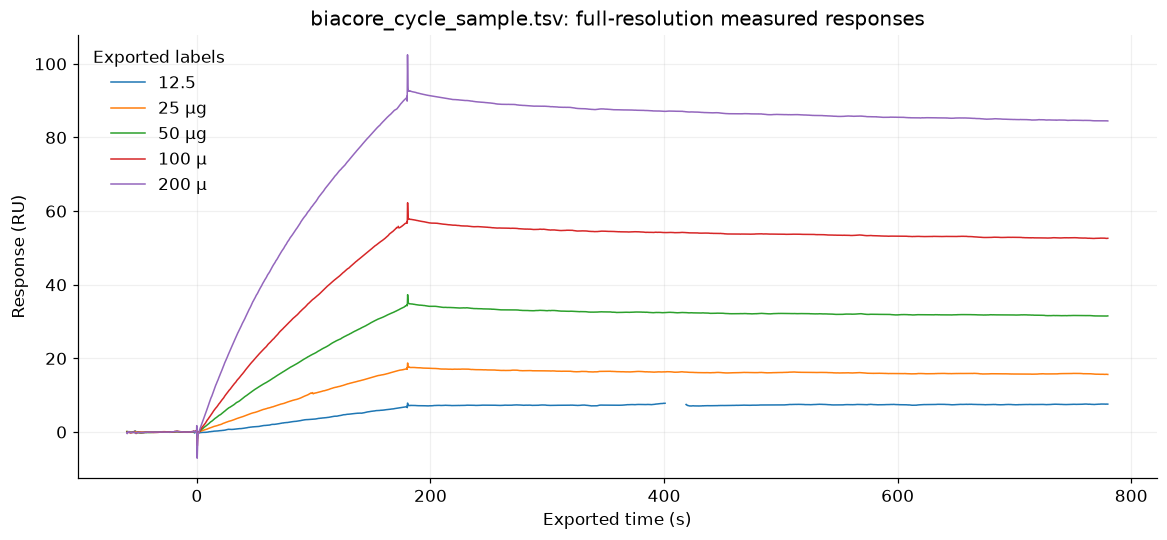

In [6]:
fig, ax = plt.subplots(figsize=(10.5, 4.8), constrained_layout=True)
axes = [ax]
for i, label in enumerate(plot_labels):
    time = np.concatenate(experiment.xs[i])
    response = np.concatenate(experiment.ys[i])
    breaks = np.flatnonzero(np.diff(time) > 3 * np.median(np.diff(time))) + 1
    segments = np.split(np.arange(len(time)), breaks)
    for axis in axes:
        for j, indices in enumerate(segments):
            axis.plot(time[indices], response[indices], color=f"C{i}", linewidth=1,
                      label=label if j == 0 else None)
for axis in axes:
    axis.set(xlabel="Exported time (s)", ylabel="Response (RU)")
    axis.legend(frameon=False, title="Exported labels")
    axis.grid(alpha=0.18)
ax.set_title("biacore_cycle_sample.tsv: full-resolution measured responses")
plt.show()

## Check the retained points and import partitions

The original times remain in `xs`; `ys` contains the measured responses. The
five curve identities/concentrations come from page 1 of the published report.
Association and dissociation windows come from the original sample sheet.
Only observations in the stated protocol window are included in this excerpt.

In [7]:
imported_points = pd.DataFrame([
    {
        "Curve": curve_ids[i],
        "Baseline points": len(experiment.xs[i][0]),
        "Association points": len(experiment.xs[i][1]),
        "Dissociation points": len(experiment.xs[i][2]),
        "Total points": sum(len(step) for step in experiment.xs[i]),
        "First exported time (s)": np.concatenate(experiment.xs[i])[0],
        "Last exported time (s)": np.concatenate(experiment.xs[i])[-1],
    }
    for i in range(experiment.no_sensors)
])
display(imported_points)
display(experiment.df_steps[["Name", "Type", "Start"]])

,Curve,Baseline points,Association points,Dissociation points,Total points,First exported time (s),Last exported time (s)
0,Curve 1,600,1800,5821,8221,-59.96,779.94
1,Curve 2,600,1791,6000,8391,-59.96,779.94
2,Curve 3,600,1800,6000,8400,-59.96,779.94
3,Curve 4,600,1792,6000,8392,-59.96,779.94
4,Curve 5,600,1800,6000,8400,-59.96,779.94


,Name,Type,Start
0,Baseline,BASELINE,-59.96
1,Association,ASSOC,0.00
2,Dissociation,DISASSOC,180.00


All finite observations within the selected protocol window remain available in the import. The following fit uses an association-aligned copy of all five curves.

## Published one-site model

The original T200 sample sheet specifies association **0–180 s**, dissociation
**180–780 s**, regeneration, and association bulk shifts. Fit a **one-site
Langmuir model with local Smax**, using pyKinGenie's existing fitter. The
author report uses fitting #1 with local Rmax and bulk-shift handling. The
existing pyKinGenie one-site method does not fit independent RI offsets,
so its settings differ from the reference. The selected cycles
18–22 have concentrations **0.2217, 0.4434, 0.8868, 1.774, 3.547 µM**,
matching page 1 of the author sensorgram report.

Reference: [Li et al., TitrationAnalysis](https://pmc.ncbi.nlm.nih.gov/articles/PMC10667272/) and the [author report](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Titration%20Analysis_T200_Report_Example.csv). The original CSV is included locally with provenance in [SOURCES.md](data/spr_exports/SOURCES.md).

This notebook fits the **same five concentration curves** as the author report,
within the same nominal protocol windows. No alternative models or model selection are run.

## Align association and use pyKinGenie's fitting workflow

Call `align_association(inplace=True, npoints=10)` on a copy. It subtracts the
mean of the last 10 baseline points from every phase without changing the
imported time arrays. The original experiment and raw plot remain unchanged.

Use `KineticsAnalyzer.generate_fittings(..., trim_time=0)` to match the source
sheet's **Asso. Skip = 0** and **Disso. Skip = 0**. The excerpt already limits
observations to the published protocol windows. Keep all imported observations
at their native sampling; no thinning,
interpolation, smoothing, custom model equations or custom optimizer are used.
The package's `get_step_xy` supplies the step-relative time arrays.

`submit_steady_state_fitting()` provides the initialization required by the
standard kinetic fitter. Only the final one-site kinetic result is shown.

In [8]:
from copy import deepcopy

fit_experiment = deepcopy(experiment)
fit_experiment.align_association(inplace=True, npoints=10)

fit_analyzer = KineticsAnalyzer()
fit_analyzer.add_experiment(fit_experiment, fit_experiment.name)
fit_analyzer.merge_ligand_conc_df()
messages = fit_analyzer.generate_fittings(
    fit_analyzer.combined_ligand_conc_df.copy(), trim_time=0,
)
print("\n".join(messages))
fit_analyzer.submit_steady_state_fitting()

Creating a new fitting object for sample: AE.A244


In [9]:
# This is the existing pyKinGenie KineticsFitter method.
fitter = next(iter(fit_analyzer.fittings.values()))
fitter.fit_one_site_assoc_and_disso(shared_smax=False, calc_loo=False)
display(fitter.fit_params_kinetics)

,Concentration [µM],Kd [µM],k_off [1/s],Smax,(Derived) k_on [1/µM/s]
0,0.2217,0.071797,0.000128,109.774702,0.001776
1,0.4434,0.071797,0.000128,128.871072,0.001776
2,0.8868,0.071797,0.000128,138.375687,0.001776
3,1.7740,0.071797,0.000128,130.666647,0.001776
4,3.5470,0.071797,0.000128,133.473911,0.001776


## One-site fit from pyKinGenie

The package's `plot_association_dissociation` displays observations and the
fitted curves returned by `KineticsFitter`. Its plotting budget limits displayed
points only; the fit uses all observations allowed by `trim_time`.

**Check the published figure:** [Author fitted-sensorgram PDF](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Titration%20Analysis_T200_Sensorgram_Example.pdf).
Locate Chip 1 / Channel 2, fitting #1 (**local Rmax**); ligand CH31, analyte AE.A244. The same five concentrations are shown on **page 1** of that report.

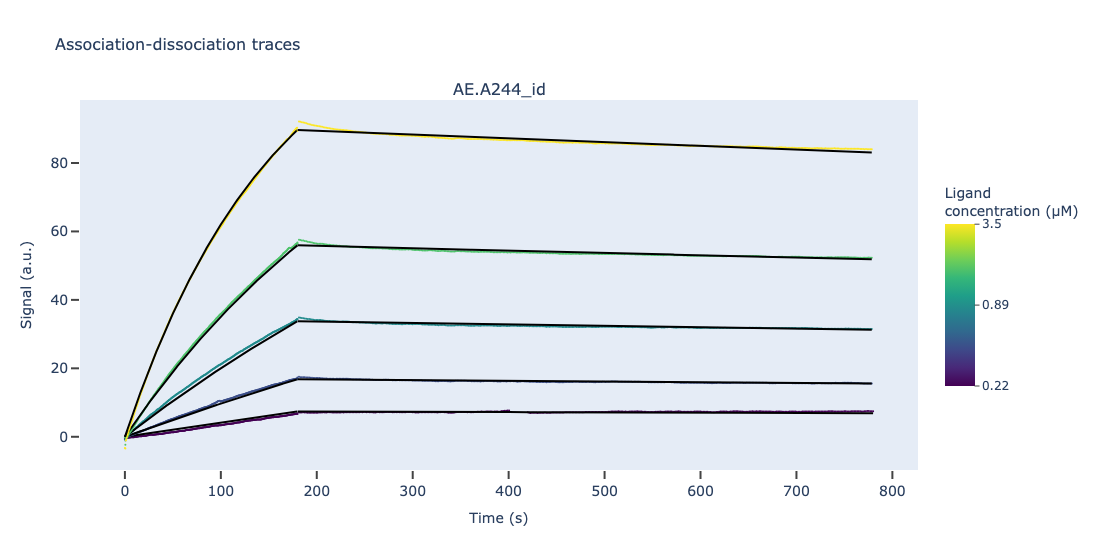

In [10]:
from pykingenie import plot_association_dissociation
from IPython.display import Image

fig_fit = plot_association_dissociation(
    fit_analyzer, split_by_smax_id=False,
    plot_width=22, plot_height=11, marker_size=2, line_width=2,
)
display(Image(data=fig_fit.to_image(format="png", width=1100, height=550)))

## Compare pyKinGenie's fitted parameters with the published values

The table uses `fitter.Kd` and `fitter.k_off` directly. kon is their ratio.
Only unit conversion and percentage differences are calculated below.
Local Smax values are shown in the library result table above.

**Check the published numbers:** [Original parameter table (PDF)](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Titration%20Analysis_T200_Report_Example.pdf) or [machine-readable values (CSV)](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Titration%20Analysis_T200_Report_Example.csv).
Use Chip 1 / Channel 2, fitting #1 (**local Rmax**); ligand CH31, analyte AE.A244. These are the values in the Published column below.

In [11]:
reference = fit_metadata["literature_reference"]["parameters_molar"]
comparison = pd.DataFrame({
    "Parameter": ["kon", "koff", "Kd"],
    "Unit": ["M⁻¹ s⁻¹", "s⁻¹", "nM"],
    "Published": [reference["kon"], reference["koff"], reference["Kd"] * 1e9],
    "pyKinGenie": [fitter.k_off / fitter.Kd * 1e6, fitter.k_off, fitter.Kd * 1e3],
})
comparison["Difference (%)"] = 100 * (comparison["pyKinGenie"] / comparison["Published"] - 1)
display(comparison.style.format({
    "Published": "{:.5g}", "pyKinGenie": "{:.5g}", "Difference (%)": "{:+.2f}",
}))

,Parameter,Unit,Published,pyKinGenie,Difference (%)
0,kon,M⁻¹ s⁻¹,1812.1,1776,-1.99
1,koff,s⁻¹,0.00011912,0.00012751,+7.05
2,Kd,nM,65.736,71.797,+9.22


## Scope of the comparison

These are the results of pyKinGenie's existing fitting API. Both analyses now
use the same five curve identities, concentrations and nominal association/
dissociation windows; those selections were verified against page 1 of the
author sensorgram report and the companion sample sheet.

Differences in alignment, sampling, time handling and model settings remain.
The standard method does not add the author's T200 bulk-shift parameters or
reconstruct Carterra's absolute occupied state/full non-regenerative history.
The comparison table shows the library results without custom corrections.
Matching the curve selection therefore does not imply an exact reproduction
or validate intrinsic kinetic constants.

See [SPR_FITTING.md](SPR_FITTING.md) for API calls and reference reports.